# WaNet Backdoor Attack & Adaptive Defense Pipeline (v4 + v5 STRIP, Kaggle)

**Goal:** Train WaNet-poisoned ResNet-18 models at **1% / 5% / 10%** poison rates, run pre-defense detection (AC + STRIP), let the Adaptive Controller route (thresholds frozen, zero recalibration), then run **every defense on every condition** (FT, ANP, NAD, BaEraser-lite) so the controller's pick can be compared against always-X and the oracle.

**v4 vs v3 (after reading the repo files `core/detection.py`, `defenses/nad.py`, `defenses/baeraser_lite.py`):** (a) AC now reproduces the repo's `run_ac` pipeline (whole poisoned train set, predicted-target group, StandardScaler, n_init=50), because v3's unscaled labelled-class clustering would not be comparable to the frozen 0.40 silhouette threshold; (b) NAD calls the repo's `nad_full_pipeline` exactly like the Blended notebook instead of a notebook re-implementation; (c) FT uses no augmentation, as the Blended FT does; (d) BaEraser assumptions (sigmoid range, `TriggerOperator` base, config key, no leak via `ca_loader`) were checked against the source.

**What changed vs v2**
1. **Same Drive root and same held-out split as Blended v3** (`ps-capstone4`; defense 2,000 / select 500 / report 7,500, obtained from `baeraser_lite.split_test_set` + `make_select_split` when the repo is importable, and cross-checked against `eval_split_seed2027.npz`). v2 built its own 2,500/500/7,000 permutation, so WaNet numbers would not have been comparable with Blended. The notebook now refuses to run on a non-Blended split unless you allow it explicitly.
2. **Training recipe matches the Blended notebook** (SGD, lr 0.1, wd 5e-4, 80 epochs, cosine, batch 128 -- the cell marked "template config, DO NOT MODIFY"). v2 used lr 0.01 / 100 epochs / wd 1e-4 from a planning doc; check that against how your BadNets/SK checkpoints were really trained and edit `CFG['train']` if they differ.
3. **BaEraser-lite adapter is real**: v2 imported a function that does not exist, so the controller's BaEraser route could never execute. v3 adds a WaNet trigger operator (defender is told the family, `k` and `s`, never the key) and drives `BL.recover_trigger_pool` -> `BL.baeraser_unlearning` exactly as the Blended BaEraser notebook does. **Untested against your repo (see the self-test cell); failures are logged as `baeraser_unavailable` / `baeraser_failed`, never silently substituted.**
4. **Defense settings aligned with Blended v3.x**: FT 15 epochs + patience 3; ANP fine threshold grid + 1 pp select-slice margin + "largest threshold within the budget" rule; NAD teacher-lr search on the select slice; `ca_drop_exceeds_tolerance` flag on the report half.
5. **Smoke-test mode** (`CFG['smoke']`): 20 epochs, separate output folder, can never be mixed with paper numbers.
6. **Extras**: STRIP AUROC (threshold-free), clean-image->airplane rate (is a ~0% ASR just "stopped predicting airplane"?), trigger stealth metrics (PSNR / L-inf) and a visual sanity figure, CIFAR lookup falls back to a wider Drive search before downloading.
7. Kept from v2: trigger applied *after* crop/flip, AC on the target-class group (PCA-2D), seeded 100-overlay STRIP from the defense split, controller decision executed, checkpoint resume.

> **Note on the "trigger after augmentation" choice.** v2 claimed this follows the original WaNet. To my recollection the official code (and BackdoorBench) warp first and apply crop/flip/rotation to the whole batch afterwards. Applying the warp after augmentation keeps train and test triggers pixel-aligned, which usually makes the backdoor *easier* to implant, so it is a defensible choice, but report it as a deviation, not as "as in the paper".

> **Runtime (rough, T4):** 3 rates x 80 epochs is about 2 h of training, plus roughly 1.5 to 2.5 h for the full defense matrix (BaEraser-lite dominates). Training resumes from `*_resume.pt` if Colab disconnects. **Run once with `CFG['smoke']=True` first.**

## 1. Kaggle project root + GitHub setup

In [1]:
import os, sys, shutil, glob, time, json, copy, random, subprocess, traceback, hashlib
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules

# Kaggle: attached datasets are read-only, so copy the project folder into /kaggle/working once and use that as the root.
# The dataset slug is auto-detected (first /kaggle/input/*/ps-capstone4); edit KAGGLE_INPUT by hand if you have several.
_found = sorted(glob.glob('/kaggle/input/*/ps-capstone4'))
KAGGLE_INPUT = Path(_found[0]) if _found else Path('/kaggle/input/datasets/archi829/wanet-defense/ps-capstone4')
DRIVE_ROOT = Path('/kaggle/working/ps-capstone4')
if not DRIVE_ROOT.exists():
    if not KAGGLE_INPUT.exists():
        raise FileNotFoundError(f"Dataset folder not found: {KAGGLE_INPUT}")
    shutil.copytree(KAGGLE_INPUT, DRIVE_ROOT)
print("Project root:", DRIVE_ROOT)

# Shared repo (core/, defenses/): same URL as the Blended notebooks
REPO_URL = 'https://github.com/Aritraghoshdastidar/adaptive-backdoor-defense.git'
REPO_DIR = '/kaggle/working/adaptive-backdoor-defense'
try:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(['git', 'clone', REPO_URL, REPO_DIR], check=True, timeout=300)
    else:
        r = subprocess.run(['git', '-C', REPO_DIR, 'pull', '--ff-only'], capture_output=True, text=True, timeout=120)
        print('git pull:', (r.stdout.strip() or r.stderr.strip())[:200])
except Exception as e:
    print('repo clone/pull failed:', e)
if os.path.isdir(REPO_DIR):
    sys.path.insert(0, REPO_DIR)

# Repo pieces are OPTIONAL for the attack/detection/FT/ANP/NAD cells, REQUIRED for BaEraser-lite and for the exact Blended split.
# The repo keeps these files in core/defenses/ (older Blended runs copied them to defenses/), so look in both places.
import importlib, importlib.util

def _load_repo_module(mod_name, filename):
    cands = [os.path.join(REPO_DIR, 'defenses', filename), os.path.join(REPO_DIR, 'core', 'defenses', filename),
             str(DRIVE_ROOT / 'defenses' / filename), str(DRIVE_ROOT / filename)]
    for p in cands:
        if os.path.isfile(p):
            spec = importlib.util.spec_from_file_location(mod_name, p)
            mod = importlib.util.module_from_spec(spec); sys.modules[mod_name] = mod
            spec.loader.exec_module(mod)
            print(f'  loaded {filename} from {p}')
            return mod
    raise FileNotFoundError(f'{filename} not found in: ' + ' | '.join(cands))

try:
    BL = _load_repo_module('baeraser_lite', 'baeraser_lite.py')
    from core.metrics import calculate_ca, calculate_asr
    for fn in ('split_test_set', 'make_select_split', 'recover_trigger_pool', 'baeraser_unlearning'):
        assert hasattr(BL, fn), f'baeraser_lite.{fn} missing (old file?)'
    print('Repo OK: baeraser_lite + core.metrics importable.')
except Exception as e:
    raise RuntimeError(f'Repo import failed ({type(e).__name__}: {e}). Fix the repo path/clone before running; do not proceed with a partial defense matrix.')
try:
    nad_mod = _load_repo_module('nad_defense', 'nad.py')
    for fn in ('nad_full_pipeline', 'select_teacher_lr', 'build_nad_teacher'):
        assert hasattr(nad_mod, fn)
    print('Repo OK: nad importable.')
except Exception as e:
    raise RuntimeError(f'nad import failed ({type(e).__name__}: {e}). Fix before running; do not proceed with a partial defense matrix.')


Project root: /kaggle/working/ps-capstone4


Cloning into '/kaggle/working/adaptive-backdoor-defense'...


  loaded baeraser_lite.py from /kaggle/working/adaptive-backdoor-defense/core/defenses/baeraser_lite.py
Repo OK: baeraser_lite + core.metrics importable.
  loaded nad.py from /kaggle/working/adaptive-backdoor-defense/core/defenses/nad.py
Repo OK: nad importable.


## 2. Imports and configuration

In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset
import torchvision
from torchvision.models import resnet18
from sklearn.decomposition import PCA, FastICA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, roc_auc_score
from scipy.stats import norm

PAPER_EPOCHS = 80

CFG = dict(
    seed=2027,
    target_class=0,
    smoke=False,                         # True = 20-epoch smoke test, outputs go to wanet_v3/smoke (never mixed with paper numbers)
    smoke_epochs=20,
    poison_rates=[0.01, 0.05, 0.10],     # defines the nested poison sets (always all three)
    active_rates=[0.01, 0.05, 0.10],     # which rates to train/evaluate this run (smoke test: e.g. [0.10])
    wanet=dict(k=4, s=0.5, grid_rescale=1.0, cross_ratio=2.0, grid_seed=2027),
    # Matches the Blended attack notebook ("template config, DO NOT MODIFY"): SGD lr 0.1, wd 5e-4, 80 epochs, cosine, bs 128.
    train=dict(epochs=PAPER_EPOCHS, lr=0.1, momentum=0.9, wd=5e-4, batch=128, workers=2, resume_every=10),
    asr_min_valid=50.0,                  # below this baseline ASR the attack is logged as failed; defenses are skipped
    split=dict(n_val=2500, n_select=500, seed=2027, require_blended_split=True),   # defense 2000 / select 500 / report 7500
    strip=dict(n_test=250, n_super=100, frr=0.01, formula='add', sensitivity_formula='average'),   # n_test=250 -> 250 clean + 250 triggered = 500 samples
    controller=dict(tau_ac=0.40, tau_strip=30.0),   # frozen: zero recalibration on the unseen attack
    ft=dict(epochs=15, lr=1e-4, batch=128, patience=3),
    anp=dict(eps=0.4, steps=1, alpha=0.2, mask_lr=0.2, iters=2000, batch=128, max_ca_drop=5.0, select_margin_pp=1.0,
             thresholds=sorted(set([round(float(t), 2) for t in np.arange(0.05, 0.9001, 0.05)] +
                                   [round(float(t), 2) for t in np.arange(0.20, 0.5001, 0.01)]))),
    nad=dict(teacher_epochs=10, lr_grid=(0.02, 0.01, 0.005, 0.001), epochs=10, betas=(500, 1000, 1000),
             max_ca_drop=5.0),     # passed to defenses/nad.py (student lr 0.01, batch 64, as in the Blended notebook)
    baeraser=dict(fresh_select_k=1, ca_select_margin=0.01),
    run_defenses='all',                  # 'all' = full matrix; 'controller_only' = just the routed defense
    post_strip=True,
)
if CFG['smoke']:
    CFG['train']['epochs'] = CFG['smoke_epochs']
    CFG['asr_min_valid'] = 0.0           # smoke test: let the defense plumbing (incl. BaEraser adapter) run even if 20 epochs gives a weak backdoor
else:
    assert CFG['train']['epochs'] == PAPER_EPOCHS, 'paper runs must use the full recipe; set CFG["smoke"]=True for short runs'
assert set(CFG['active_rates']) <= set(CFG['poison_rates'])

SEED = CFG['seed']
TARGET = CFG['target_class']
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

WANET_DIR = DRIVE_ROOT / 'wanet_v3'
OUT_DIR = WANET_DIR / ('smoke' if CFG['smoke'] else 'paper')
CKPT_DIR = OUT_DIR / 'checkpoints'
RESULTS_DIR = OUT_DIR / 'results'
ACT_DIR = OUT_DIR / 'activations'
FIG_DIR = OUT_DIR / 'figures'
IDX_DIR = WANET_DIR / 'indices'            # shared between smoke and paper runs (same keys, same poison sets)
for d in (CKPT_DIR, RESULTS_DIR, ACT_DIR, FIG_DIR, IDX_DIR, DRIVE_ROOT / 'data'):
    d.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def tag_of(rate): return f'pr{int(round(rate * 100)):02d}'
def cond_of(rate): return f'{int(round(rate * 100))}%'

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MEAN_T = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
STD_T = torch.tensor(STD, device=device).view(1, 3, 1, 1)
def normalize(x01): return (x01 - MEAN_T) / STD_T
print('Device:', device, '| seed', SEED, '| active rates', CFG['active_rates'], '| epochs', CFG['train']['epochs'],
      '| mode', 'SMOKE' if CFG['smoke'] else 'PAPER', '| out', OUT_DIR)

Device: cuda | seed 2027 | active rates [0.01, 0.05, 0.1] | epochs 80 | mode PAPER | out /kaggle/working/ps-capstone4/wanet_v3/paper


## 3. Dataset (reuse CIFAR-10 from Drive) and the Blended v3 held-out split
CIFAR-10 is copied from Drive to Colab-local storage (fixed path first, then a bounded search, then a wider Drive search like the Blended notebook, then a one-time download saved back to Drive). All training and evaluation run on local storage.

The **CIFAR-10 test set** is split once into **val = 2,500** (defense budget 2,000 + select slice 500) and **report = 7,500**, using the *same functions* as the Blended FT/ANP/NAD and BaEraser notebooks. Defenses never touch the report split and never touch the poisoned model's training images. If the repo is not importable the split falls back to the shared `eval_split_seed2027.npz` (exact val/report, approximate def/select sub-split) or, failing that, a local stratified split; with `require_blended_split=True` the latter two stop the run so you cannot silently produce non-comparable numbers.

In [3]:
LOCAL_DATA_DIR = './data'
CIFAR_FOLDER = 'cifar-10-batches-py'
DRIVE_CIFAR_DIR = DRIVE_ROOT / 'data' / CIFAR_FOLDER

def _has_cifar(p): return (Path(p) / 'data_batch_1').exists() and (Path(p) / 'test_batch').exists()

def ensure_cifar_local():
    local = Path(LOCAL_DATA_DIR) / CIFAR_FOLDER
    if _has_cifar(local):
        print('CIFAR-10 already local.'); return
    Path(LOCAL_DATA_DIR).mkdir(exist_ok=True)
    src = DRIVE_CIFAR_DIR if _has_cifar(DRIVE_CIFAR_DIR) else None
    if src is None:     # bounded search inside ps-capstone4/
        hits = [h for h in glob.glob(str(DRIVE_ROOT / '**' / CIFAR_FOLDER), recursive=True) if _has_cifar(h)]
        src = Path(hits[0]) if hits else None
    if src is None and IN_COLAB:   # wide search (same as Blended notebooks), one time
        hits = [h for h in glob.glob('/content/drive/MyDrive/**/' + CIFAR_FOLDER, recursive=True) if _has_cifar(h)]
        src = Path(hits[0]) if hits else None
    if src is not None:
        print('Copying CIFAR-10 from Drive:', src)
        shutil.copytree(src, local, dirs_exist_ok=True)
    else:
        print('Not on Drive: downloading once and saving to Drive.')
        torchvision.datasets.CIFAR10(root=LOCAL_DATA_DIR, train=True, download=True)
        DRIVE_CIFAR_DIR.parent.mkdir(parents=True, exist_ok=True)
        if not DRIVE_CIFAR_DIR.exists():
            shutil.copytree(local, DRIVE_CIFAR_DIR)

ensure_cifar_local()
trainset = torchvision.datasets.CIFAR10(root=LOCAL_DATA_DIR, train=True, download=False)
testset = torchvision.datasets.CIFAR10(root=LOCAL_DATA_DIR, train=False, download=False)
train_x, train_y = trainset.data, np.array(trainset.targets)     # uint8 NHWC
test_x, test_y = testset.data, np.array(testset.targets)
print('train', train_x.shape, 'test', test_x.shape)

def to01(arr_uint8):
    return torch.from_numpy(arr_uint8).permute(0, 3, 1, 2).float().div(255.0)

# Fixed split: LOAD ONLY. Never regenerate.
SPLIT_FILE = IDX_DIR / 'wanet_split_idx.npz'
if not SPLIT_FILE.is_file():
    raise FileNotFoundError(f"Missing fixed WaNet split: {SPLIT_FILE}")

with np.load(SPLIT_FILE, allow_pickle=False) as z:
    missing = {'def_idx', 'sel_idx', 'rep_idx'} - set(z.files)
    if missing:
        raise KeyError(f"{SPLIT_FILE} is missing arrays: {sorted(missing)}")
    def_idx = z['def_idx'].astype(np.int64)
    sel_idx = z['sel_idx'].astype(np.int64)
    rep_idx = z['rep_idx'].astype(np.int64)

assert len(def_idx) == 2000
assert len(sel_idx) == 500
assert len(rep_idx) == 7500
assert len(set(def_idx) & set(sel_idx)) == 0
assert len(set(def_idx) & set(rep_idx)) == 0
assert len(set(sel_idx) & set(rep_idx)) == 0
assert len(np.unique(np.concatenate([def_idx, sel_idx, rep_idx]))) == 10000
assert np.all(np.concatenate([def_idx, sel_idx, rep_idx]) >= 0)
assert np.all(np.concatenate([def_idx, sel_idx, rep_idx]) < len(test_y))

SPLIT_SRC = f'saved fixed split: {SPLIT_FILE.name}'
SPLIT_COMPAT = True
print("Loaded fixed split:", SPLIT_FILE)
print("Defense:", len(def_idx), "| Selection:", len(sel_idx), "| Report:", len(rep_idx))

# Cross-check against the shared Blended split (verification only; never used to generate)
SHARED_SPLIT = DRIVE_ROOT / 'shared' / 'splits' / 'eval_split_seed2027.npz'
if not SHARED_SPLIT.is_file():
    raise FileNotFoundError(f"Required shared evaluation split missing: {SHARED_SPLIT}")

with np.load(SHARED_SPLIT, allow_pickle=False) as z:
    assert set(def_idx) | set(sel_idx) == set(z['val_idx'].astype(np.int64)), \
        "WaNet defense + selection indices differ from Blended val split"
    assert np.array_equal(np.sort(rep_idx), np.sort(z['report_idx'].astype(np.int64))), \
        "WaNet report split differs from Blended report split"
print("Shared Blended split cross-check passed.")

Copying CIFAR-10 from Drive: /kaggle/working/ps-capstone4/data/cifar-10-batches-py
train (50000, 32, 32, 3) test (10000, 32, 32, 3)
Loaded fixed split: /kaggle/working/ps-capstone4/wanet_v3/indices/wanet_split_idx.npz
Defense: 2000 | Selection: 500 | Report: 7500
Shared Blended split cross-check passed.


## 4. WaNet trigger (Nguyen & Tran, ICLR 2021) and poison construction
The warp grid is cached on Drive so every notebook uses the identical key. Poison sets are **nested** across rates (1% ⊂ 5% ⊂ 10%), and noise-mode (cross) samples are drawn from a disjoint block of the same permutation.

In [4]:
WK = CFG['wanet']

def make_warp_grid(h=32, k=WK['k'], s=WK['s'], seed=WK['grid_seed'], rescale=WK['grid_rescale']):
    g = torch.Generator().manual_seed(seed)
    ins = torch.rand(1, 2, k, k, generator=g) * 2 - 1
    ins = ins / ins.abs().mean()
    noise = F.interpolate(ins, size=h, mode='bicubic', align_corners=True).permute(0, 2, 3, 1)
    a = torch.linspace(-1, 1, h)
    xx, yy = torch.meshgrid(a, a, indexing='ij')
    identity = torch.stack((yy, xx), 2)[None]
    return torch.clamp((identity + s * noise / h) * rescale, -1, 1)

grid_path = IDX_DIR / f"wanet_warp_grid_k{WK['k']}_s{WK['s']}_seed{WK['grid_seed']}.pt"
if not grid_path.is_file():
    raise FileNotFoundError(f"Required fixed WaNet warp grid missing: {grid_path}")
WARP_GRID = torch.load(grid_path, map_location='cpu', weights_only=True)
assert WARP_GRID.shape == (1, 32, 32, 2), f"Unexpected warp grid shape: {WARP_GRID.shape}"
WARP_GRID = WARP_GRID.to(device)

def apply_wanet(x01):
    """x01: (B,3,H,W) in [0,1]."""
    g = WARP_GRID.to(x01.device).expand(x01.size(0), -1, -1, -1)
    return F.grid_sample(x01, g, align_corners=True).clamp(0, 1)

def apply_noise_warp(x01, generator=None):
    """Noise mode: warp field + per-sample random jitter; the label is NOT changed."""
    B, _, h, _ = x01.shape
    if generator is None:
        jit = torch.rand(B, h, h, 2, device=x01.device)
    else:
        jit = torch.rand(B, h, h, 2, generator=generator).to(x01.device)
    jit = (jit * 2 - 1) / h
    g = torch.clamp(WARP_GRID.to(x01.device) + jit, -1, 1)
    return F.grid_sample(x01, g, align_corners=True).clamp(0, 1)

# Fixed poison and cross indices: LOAD ONLY
POISON = {}
for r in CFG['poison_rates']:
    t = tag_of(r)
    poison_file = IDX_DIR / f'wanet_poison_idx_{t}.npy'
    cross_file = IDX_DIR / f'wanet_cross_idx_{t}.npy'
    for f in (poison_file, cross_file):
        if not f.is_file():
            raise FileNotFoundError(f"Required fixed WaNet index file missing: {f}")
    p = np.load(poison_file, allow_pickle=False)
    c = np.load(cross_file, allow_pickle=False)
    assert len(np.unique(p)) == len(p), f"Duplicate poison indices in {t}"
    assert len(np.unique(c)) == len(c), f"Duplicate cross indices in {t}"
    assert len(p) == int(round(r * len(train_y)))
    assert len(c) == int(round(WK['cross_ratio'] * len(p)))
    assert np.all((p >= 0) & (p < len(train_y)))
    assert np.all((c >= 0) & (c < len(train_y)))
    assert not np.isin(p, c).any()
    POISON[t] = (p, c)
    print(f"{t}: loaded poison={len(p)} cross={len(c)}")

# Verify the poison sets are nested
ps = [set(POISON[tag_of(r)][0]) for r in sorted(CFG['poison_rates'])]
assert all(ps[i] <= ps[i + 1] for i in range(len(ps) - 1)), "Poison sets are not nested"

pr01: loaded poison=500 cross=1000
pr05: loaded poison=2500 cross=5000
pr10: loaded poison=5000 cross=10000


## 5. Model, evaluation helpers, held-out tensors

In [5]:
def get_resnet18(num_classes=10):
    m = resnet18(weights=None)
    m.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    m.maxpool = nn.Identity()
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m

def to01_dev(arr, bs=2000):
    return torch.cat([to01(arr[i:i + bs]).to(device) for i in range(0, len(arr), bs)])

# Held-out tensors (GPU)
rep_x, rep_y = to01_dev(test_x[rep_idx]), torch.from_numpy(test_y[rep_idx])
sel_x, sel_y = to01_dev(test_x[sel_idx]), torch.from_numpy(test_y[sel_idx])
def_x, def_y = to01_dev(test_x[def_idx]), torch.from_numpy(test_y[def_idx])
rep_nt = (rep_y != TARGET)
rep_trig = apply_wanet(rep_x[rep_nt.to(device)])                                   # triggered, non-target
rep_noise = apply_noise_warp(rep_x[rep_nt.to(device)], generator=torch.Generator().manual_seed(SEED))
print('report:', rep_x.shape[0], '| non-target triggered pool:', rep_trig.shape[0])

@torch.no_grad()
def predict(model, x01, bs=1000):
    model.eval(); out = []
    for i in range(0, len(x01), bs):
        out.append(model(normalize(x01[i:i + bs].to(device))).argmax(1).cpu())
    return torch.cat(out)

def acc_on(model, x01, y):
    return 100.0 * (predict(model, x01) == y).float().mean().item()

def evaluate(model):
    """All numbers on the REPORT split only."""
    pred_c = predict(model, rep_x)
    ca = 100.0 * (pred_c == rep_y).float().mean().item()
    tgt = rep_y == TARGET
    tgt_acc = 100.0 * (pred_c[tgt] == rep_y[tgt]).float().mean().item()
    clean_tgt_rate = 100.0 * (pred_c[~tgt] == TARGET).float().mean().item()   # clean non-target images predicted as airplane
    asr = 100.0 * (predict(model, rep_trig) == TARGET).float().mean().item()
    noise_asr = 100.0 * (predict(model, rep_noise) == TARGET).float().mean().item()   # should be LOW if noise mode worked
    return dict(ca=ca, asr=asr, noise_asr=noise_asr, target_class_acc=tgt_acc, clean_target_rate=clean_tgt_rate)

class AugSet(Dataset):
    """uint8 NHWC arrays -> float [0,1] CHW with crop(4)+flip. Trigger is applied later, on GPU, AFTER augmentation."""
    def __init__(self, x, y, kind=None):
        self.x, self.y = x, np.asarray(y)
        self.kind = np.zeros(len(self.y), dtype=np.int64) if kind is None else kind
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        img = torch.from_numpy(self.x[i]).permute(2, 0, 1).float().div_(255.0)
        img = F.pad(img, (4, 4, 4, 4))
        dy, dx = torch.randint(0, 9, (2,)).tolist()
        img = img[:, dy:dy + 32, dx:dx + 32]
        if torch.rand(1).item() < 0.5: img = img.flip(2)
        return img, int(self.y[i]), int(self.kind[i])

def make_loader(ds, batch, shuffle=True, workers=2, persistent=False):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, num_workers=workers, generator=g,
                      worker_init_fn=seed_worker, persistent_workers=(persistent and workers > 0))
print('helpers ready')

report: 7500 | non-target triggered pool: 6750
helpers ready


## 5b. Trigger sanity check and stealth metrics
Look at this figure before launching a long run: the warped image should be visually near-identical to the clean one (WaNet's selling point), and the noise-mode image should differ from the warped one. PSNR / L-inf are logged so the paper can state how visible the trigger is.

Stealth (1000 report images): {'psnr_mean': 29.225, 'psnr_min': 23.587, 'linf_mean': 0.221, 'linf_max': 0.411}


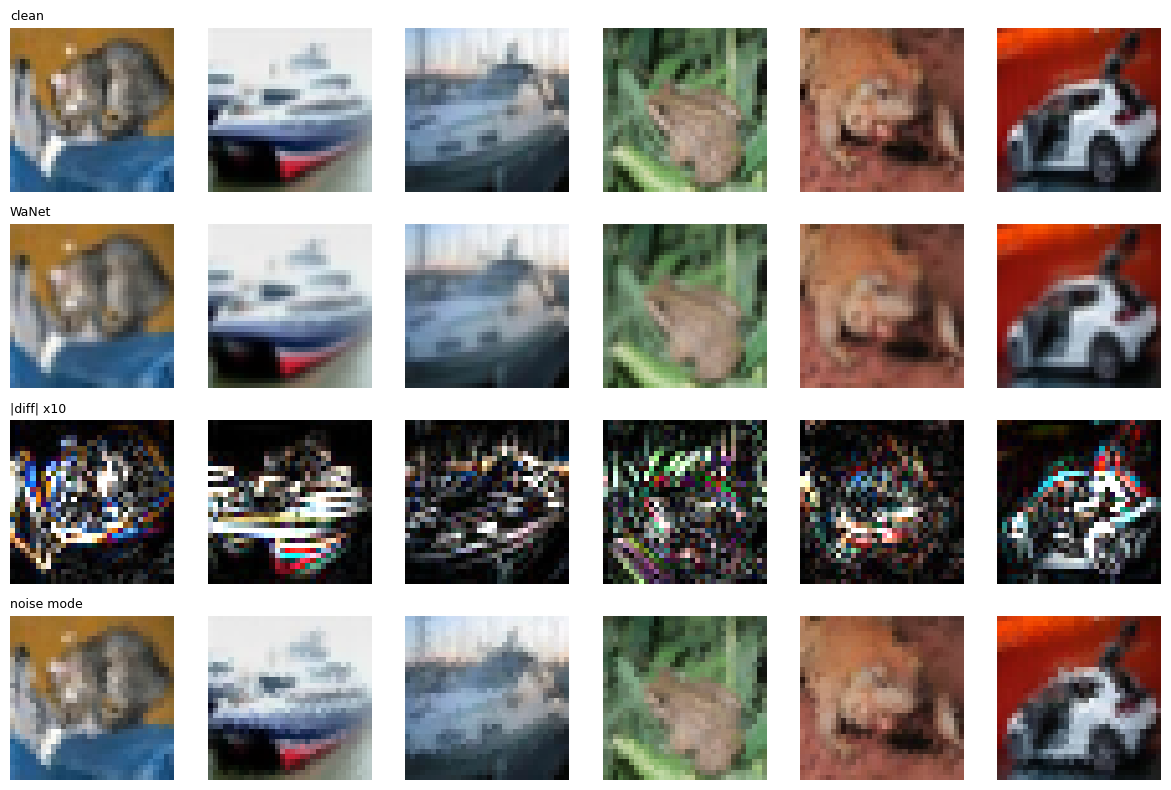

In [6]:
@torch.no_grad()
def stealth_stats(x01):
    w = apply_wanet(x01)
    mse = ((w - x01) ** 2).flatten(1).mean(1).clamp_min(1e-12)
    psnr = (10 * torch.log10(1.0 / mse))
    linf = (w - x01).abs().flatten(1).max(1).values
    return dict(psnr_mean=float(psnr.mean()), psnr_min=float(psnr.min()), linf_mean=float(linf.mean()), linf_max=float(linf.max()))

_ss = stealth_stats(rep_x[:1000]); print('Stealth (1000 report images):', {k: round(v, 3) for k, v in _ss.items()})
json.dump(_ss, open(OUT_DIR / 'wanet_stealth.json', 'w'))

_n = 6
_c = rep_x[:_n]; _w = apply_wanet(_c); _nz = apply_noise_warp(_c, generator=torch.Generator().manual_seed(SEED))
fig, ax = plt.subplots(4, _n, figsize=(2 * _n, 8))
for j in range(_n):
    for r, (img, ttl) in enumerate([(_c[j], 'clean'), (_w[j], 'WaNet'), ((_w[j] - _c[j]).abs() * 10, '|diff| x10'), (_nz[j], 'noise mode')]):
        ax[r, j].imshow(img.clamp(0, 1).permute(1, 2, 0).cpu().numpy()); ax[r, j].axis('off')
        if j == 0: ax[r, j].set_title(ttl, fontsize=9, loc='left')
plt.tight_layout(); plt.savefig(FIG_DIR / 'wanet_trigger_samples.png', dpi=120); plt.show()

## 6. Train WaNet models (1% / 5% / 10%) with checkpoint reuse + resume

In [7]:
def train_wanet(rate):
    tag = tag_of(rate); T = CFG['train']
    ckpt = CKPT_DIR / f'resnet18_wanet_{tag}.pth'
    model = get_resnet18().to(device)
    if ckpt.exists():
        model.load_state_dict(torch.load(ckpt, map_location=device)); print(f'[{tag}] loaded {ckpt.name}')
        return model
    poison, cross = POISON[tag]
    y_p = train_y.copy(); y_p[poison] = TARGET
    kind = np.zeros(len(train_y), dtype=np.int64); kind[poison] = 1; kind[cross] = 2
    dl = make_loader(AugSet(train_x, y_p, kind), T['batch'], workers=T['workers'], persistent=True)
    opt = optim.SGD(model.parameters(), lr=T['lr'], momentum=T['momentum'], weight_decay=T['wd'])
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T['epochs'])
    crit = nn.CrossEntropyLoss(); start = 0
    resume = CKPT_DIR / f'resnet18_wanet_{tag}_resume.pt'
    if resume.exists():
        st = torch.load(resume, map_location=device, weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt']); sched.load_state_dict(st['sched']); start = st['epoch']
        print(f'[{tag}] resumed from epoch {start}')
    for ep in range(start, T['epochs']):
        model.train(); tot, cor, n = 0.0, 0, 0
        for x, y, k in dl:
            x, y, k = x.to(device), y.to(device), k.to(device)
            m1, m2 = k == 1, k == 2
            if m1.any(): x[m1] = apply_wanet(x[m1])
            if m2.any(): x[m2] = apply_noise_warp(x[m2])
            out = model(normalize(x)); loss = crit(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(y); cor += out.argmax(1).eq(y).sum().item(); n += len(y)
        sched.step()
        if (ep + 1) % 10 == 0 or ep == T['epochs'] - 1:
            ev = evaluate(model)
            print(f"[{tag}] ep {ep+1:3d}/{T['epochs']} loss {tot/n:.3f} trainacc {100*cor/n:.1f} | CA {ev['ca']:.2f} ASR {ev['asr']:.2f} noiseASR {ev['noise_asr']:.2f}")
        if (ep + 1) % T['resume_every'] == 0 and ep + 1 < T['epochs']:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), epoch=ep + 1), resume)
    torch.save(model.state_dict(), ckpt)
    if resume.exists(): resume.unlink()
    print(f'[{tag}] saved {ckpt.name}')
    return model

RUN = {}
for r in CFG['active_rates']:
    set_seed()
    RUN[tag_of(r)] = dict(rate=r, model=train_wanet(r))

[pr01] loaded resnet18_wanet_pr01.pth
[pr05] loaded resnet18_wanet_pr05.pth
[pr10] loaded resnet18_wanet_pr10.pth


## 7. Checkpoint registry: baseline CA / ASR (+ clean-model floor)
`ASR` = triggered non-target report images classified as class 0. `noise_asr` = noise-warped images (true label kept) classified as class 0; a model that only learned "any warp → target" has high noise_asr, which means noise mode did not take. The clean model (if found on Drive) gives the transfer floor, the lesson from Silent Killer.

In [8]:
base_rows = []
for t, d in RUN.items():
    ev = evaluate(d['model']); d['baseline'] = ev
    d['attack_ok'] = ev['asr'] >= CFG['asr_min_valid']
    base_rows.append(dict(tag=t, poison_condition=cond_of(d['rate']), **ev, attack_ok=d['attack_ok']))
    print(f"{t}: CA {ev['ca']:.2f} | ASR {ev['asr']:.2f} | noise-ASR {ev['noise_asr']:.2f} | target-class acc {ev['target_class_acc']:.2f} | clean->airplane {ev['clean_target_rate']:.2f} | attack_ok={d['attack_ok']}")
    if ev['noise_asr'] > 20.0:
        print(f"   !! noise-ASR {ev['noise_asr']:.1f}% > 20%: the model learned 'any warp -> target', noise mode did not take. Say so in the paper.")
    if not d['attack_ok']:
        print(f"   !! baseline ASR < {CFG['asr_min_valid']}%: attack did not implant. Detection is still logged, defenses are skipped. Report as an attack-failure finding.")

CLEAN_CKPT = DRIVE_ROOT / 'shared' / 'clean_models' / 'resnet18_clean_seed2027.pth'
if not CLEAN_CKPT.is_file():
    raise FileNotFoundError(f"Required clean checkpoint missing: {CLEAN_CKPT}")
clean_model = get_resnet18().to(device)
checkpoint = torch.load(CLEAN_CKPT, map_location=device)

clean_model.load_state_dict(checkpoint['model_state_dict'])
clean_ev = evaluate(clean_model)
print(f"Clean model floor: CA {clean_ev['ca']:.2f} | WaNet-trigger ASR {clean_ev['asr']:.2f} | noise-ASR {clean_ev['noise_asr']:.2f}")
pd.DataFrame(base_rows)

pr01: CA 94.88 | ASR 92.39 | noise-ASR 0.19 | target-class acc 95.07 | clean->airplane 0.58 | attack_ok=True
pr05: CA 94.55 | ASR 98.79 | noise-ASR 0.10 | target-class acc 95.87 | clean->airplane 0.61 | attack_ok=True
pr10: CA 94.33 | ASR 99.50 | noise-ASR 0.10 | target-class acc 96.13 | clean->airplane 0.74 | attack_ok=True
Clean model floor: CA 92.48 | WaNet-trigger ASR 0.70 | noise-ASR 2.47


,tag,poison_condition,ca,asr,noise_asr,target_class_acc,clean_target_rate,attack_ok
0,pr01,1%,94.880003,92.385185,0.192593,95.066667,0.577778,True
1,pr05,5%,94.546664,98.785186,0.103704,95.866668,0.607407,True
2,pr10,10%,94.333333,99.496299,0.103704,96.133333,0.740741,True


## 8. Pre-defense Activation Clustering (identical to the Blended pipeline)
**Fixed vs v3 after reading `core/detection.py`:** the repo's `run_ac` (used for the Blended thresholds) takes activations of the **whole poisoned training set**, keeps the samples the model **predicts** as the target class, applies a **StandardScaler**, then PCA-2D (or ICA-10D) and KMeans with **n_init=50**. v3 clustered the labelled class-0 group without scaling (n_init=10), which would give silhouettes on a different scale from the frozen 0.40 threshold. This cell now builds the same poisoned training set (poison -> warped, cross -> noise-warped, nothing else changed, no augmentation) and calls the repo's `run_ac` when importable (identical local copy otherwise). PCA-2D is the controller signal (as calibrated); ICA-10D is logged. `pdr` / `recall` use ground-truth poison indices and are internal validation only.

In [9]:
@torch.no_grad()
def feats_and_preds(model, tag, bs=2500):
    """Penultimate (avgpool) features + predictions on the FULL poisoned training set (no augmentation)."""
    model.eval(); feats, preds = [], []
    h = model.avgpool.register_forward_hook(lambda m, i, o: feats.append(o.flatten(1).cpu()))
    poison, cross = POISON[tag]; pset, cset = set(map(int, poison)), set(map(int, cross))
    gen = torch.Generator().manual_seed(SEED)
    for i in range(0, len(train_x), bs):
        idx = np.arange(i, min(i + bs, len(train_x)))
        x = to01_dev(train_x[idx])
        m1 = torch.tensor([int(k) in pset for k in idx], device=device); m2 = torch.tensor([int(k) in cset for k in idx], device=device)
        if m1.any(): x[m1] = apply_wanet(x[m1])
        if m2.any(): x[m2] = apply_noise_warp(x[m2], generator=gen)
        preds.append(model(normalize(x)).argmax(1).cpu())
    h.remove()
    return torch.cat(feats).numpy(), torch.cat(preds).numpy()

def _local_run_ac(X_all, y_pred_all, orig_idx_all, poison_idx, target_class=0, seed=SEED, use_pca=False, pca_components=2):
    """Same algorithm as core.detection.run_ac (used only if the repo is not importable)."""
    from sklearn.preprocessing import StandardScaler
    poison_flags = np.isin(orig_idx_all, poison_idx)
    idxs = np.where(y_pred_all == target_class)[0]; Xc = X_all[idxs]; poison_c = poison_flags[idxs].astype(bool)
    Xs = StandardScaler().fit_transform(Xc)
    Xr = PCA(n_components=pca_components, random_state=seed).fit_transform(Xs) if use_pca else FastICA(n_components=10, random_state=seed, max_iter=1000).fit_transform(Xs)
    cl = KMeans(n_clusters=2, n_init=50, random_state=seed).fit_predict(Xr)
    c0 = poison_c[cl == 0].mean() if (cl == 0).any() else 0; c1 = poison_c[cl == 1].mean() if (cl == 1).any() else 0
    pc = 0 if c0 > c1 else 1; sizes = np.bincount(cl, minlength=2)
    return dict(silhouette=round(float(silhouette_score(Xr, cl)), 4), suspicious_fraction=round(float(min(sizes) / len(Xc)), 4),
                PDR=round(float(poison_c[cl == pc].mean() * 100), 2), recall=round(float(poison_c[cl == pc].sum() / max(poison_c.sum(), 1) * 100), 2),
                cluster_sizes=sizes.tolist())

try:
    from core.detection import run_ac as _repo_run_ac
    AC_FN, AC_SRC = _repo_run_ac, 'core.detection.run_ac'
except Exception:
    AC_FN, AC_SRC = _local_run_ac, 'local copy of core.detection.run_ac'
print('AC implementation:', AC_SRC)

for t, d in RUN.items():
    poison, _ = POISON[t]
    X_all, y_pred = feats_and_preds(d['model'], t)
    orig_idx = np.arange(len(X_all))
    np.save(ACT_DIR / f'wanet_{int(round(d["rate"]*100))}pct_seed{SEED}.npy', X_all)
    r2 = AC_FN(X_all, y_pred, orig_idx, poison, target_class=TARGET, seed=SEED, use_pca=True, pca_components=2)
    try: ri = AC_FN(X_all, y_pred, orig_idx, poison, target_class=TARGET, seed=SEED, use_pca=False)
    except Exception as e: ri = dict(silhouette=float('nan'))
    d['ac'] = dict(silhouette=r2['silhouette'], silhouette_ica10=ri['silhouette'], suspicious_fraction=r2['suspicious_fraction'],
                   pdr=r2['PDR'], recall=r2['recall'], cluster_sizes=r2['cluster_sizes'],
                   n_pred_target=int((y_pred == TARGET).sum()), n_poison_in_pred_target=int(np.isin(np.where(y_pred == TARGET)[0], poison).sum()))
    a = d['ac']
    print(f"{t}: PCA-2D sil={a['silhouette']:.3f} | ICA-10D sil={a['silhouette_ica10']:.3f} | susp_frac={a['suspicious_fraction']:.3f} | PDR={a['pdr']:.1f}% recall={a['recall']:.1f}% | "
          f"pred->target={a['n_pred_target']} (poison inside {a['n_poison_in_pred_target']}/{len(poison)}) | sizes={a['cluster_sizes']}")
    del X_all

AC implementation: core.detection.run_ac
Target class samples:     5496
Poisoned in target class: 496
Method:              PCA-2D
Silhouette Score:    0.4416
Cluster sizes:       [1229 4267]
Suspicious fraction: 0.2236  (22.36%)
PDR:                 9.19%
Recall:              22.78%
Target class samples:     5496
Poisoned in target class: 496
Method:              ICA-10D
Silhouette Score:    0.2874
Cluster sizes:       [5003  493]
Suspicious fraction: 0.0897  (8.97%)
PDR:                 99.59%
Recall:              98.99%
pr01: PCA-2D sil=0.442 | ICA-10D sil=0.287 | susp_frac=0.224 | PDR=9.2% recall=22.8% | pred->target=5496 (poison inside 496/500) | sizes=[1229, 4267]
Target class samples:     7500
Poisoned in target class: 2497
Method:              PCA-2D
Silhouette Score:    0.3513
Cluster sizes:       [3559 3941]
Suspicious fraction: 0.4745  (47.45%)
PDR:                 69.60%
Recall:              99.20%
Target class samples:     7500
Poisoned in target class: 2497
Method:        

## 9. Pre-defense STRIP (seeded, 100 overlays/input, held-out defense pool)
Inputs, triggered inputs and overlay pool are all drawn from the **defense split** with disjoint index sets, so STRIP never touches the report split. Entropy is natural-log mean over the superimposed copies; threshold = clean-entropy normal fit at FRR = 1%. TPR needs known triggered inputs (offline-audit assumption, same as the other attacks).

> **STRIP vs repo:** `core.detection.run_strip` takes `n_samples` as the *total* (half triggered, half clean), averages the input and overlay (`(x+bg)/2`, = `overlay_alpha=0.5` here) and uses log2 entropy; the attack notebook used `n_samples=500` (250+250) with 100 overlays. Here: 500+500 inputs, 100 overlays, natural log. TPR is invariant to the log base, and the threshold comes from the same clean-entropy normal fit at FRR 1%, but 250 vs 500 samples can move TPR by a few pp near the 30% threshold. Overlays come from the defense split rather than the repo's `clean_dataset_raw`.

In [10]:
S = CFG['strip']
_rng = np.random.RandomState(SEED)
_def_nt = np.where(def_y.numpy() != TARGET)[0]
_trig_ids = _rng.choice(_def_nt, S['n_test'], replace=False)
_rest = np.setdiff1d(np.arange(len(def_y)), _trig_ids)
_clean_ids = _rng.choice(_rest, S['n_test'], replace=False)
_ovl_ids = np.setdiff1d(_rest, _clean_ids)
STRIP_CLEAN = def_x[torch.from_numpy(_clean_ids).to(device)]
STRIP_TRIG = apply_wanet(def_x[torch.from_numpy(_trig_ids).to(device)])
STRIP_OVL = def_x[torch.from_numpy(_ovl_ids).to(device)]
print('STRIP sets: clean', len(STRIP_CLEAN), '| triggered', len(STRIP_TRIG), '| overlay pool', len(STRIP_OVL))

@torch.no_grad()
def strip_entropies(model, inputs01, seed, formula):
    model.eval()
    rng = np.random.RandomState(seed)
    ents = []
    for x in inputs01:
        idx = torch.from_numpy(
            rng.choice(len(STRIP_OVL), S['n_super'], replace=False)
        ).to(device)
        s_ = x.unsqueeze(0) + STRIP_OVL[idx]
        if formula == 'average':
            s_ = s_ / 2.0
        # uint8 truncation, matching core/detection.py
        blend = torch.floor(s_.clamp(0, 1) * 255) / 255
        p = F.softmax(model(normalize(blend)), dim=1)
        ents.append(
            (-(p * torch.log(p.clamp_min(1e-12))).sum(1)).mean().item()
        )
    return np.array(ents)

def run_strip(model, seed=SEED, formula=None):
    formula = formula or S['formula']
    ec = strip_entropies(model, STRIP_CLEAN, seed, formula)
    et = strip_entropies(model, STRIP_TRIG, seed + 1, formula)
    mu, sigma = float(ec.mean()), float(ec.std())
    auroc = float(roc_auc_score(
        np.r_[np.zeros(len(ec)), np.ones(len(et))],
        -np.r_[ec, et]
    ))   # >0.5: triggered inputs have LOWER entropy
    thr = float(norm.ppf(S['frr'], loc=mu, scale=sigma))
    return dict(formula=formula, auroc=auroc,
                tpr=100.0 * float((et < thr).mean()), fpr=100.0 * float((ec < thr).mean()),
                mu=mu, sigma=sigma, thr=thr, trig_mu=float(et.mean()), ent_clean=ec, ent_trig=et)

for t, d in RUN.items():
    d['strip'] = st = run_strip(d['model'])
    np.save(ACT_DIR / f'wanet_{t}_strip_entropies_clean.npy', st['ent_clean']); np.save(ACT_DIR / f'wanet_{t}_strip_entropies_trig.npy', st['ent_trig'])
    print(f"{t}: STRIP TPR={st['tpr']:.1f}% FPR={st['fpr']:.1f}% AUROC={st['auroc']:.3f} | clean mu={st['mu']:.3f} trig mu={st['trig_mu']:.3f} thr={st['thr']:.4f}")
    # sensitivity experiment: averaging formula (logged only; never feeds the primary controller)
    d['strip_sens'] = ss = run_strip(d['model'], formula=S['sensitivity_formula'])
    print(f"   [sensitivity {S['sensitivity_formula']}] STRIP TPR={ss['tpr']:.1f}% FPR={ss['fpr']:.1f}% AUROC={ss['auroc']:.3f}")

STRIP sets: clean 250 | triggered 250 | overlay pool 1500
pr01: STRIP TPR=0.4% FPR=1.2% AUROC=0.446 | clean mu=0.421 trig mu=0.446 thr=0.1192
   [sensitivity average] STRIP TPR=0.0% FPR=1.2% AUROC=0.349
pr05: STRIP TPR=0.4% FPR=2.0% AUROC=0.453 | clean mu=0.455 trig mu=0.481 thr=0.1306
   [sensitivity average] STRIP TPR=0.0% FPR=2.0% AUROC=0.404
pr10: STRIP TPR=0.4% FPR=1.2% AUROC=0.451 | clean mu=0.452 trig mu=0.475 thr=0.1486
   [sensitivity average] STRIP TPR=0.0% FPR=1.2% AUROC=0.393


## 10. Adaptive controller (thresholds frozen)

In [11]:
TAU_AC, TAU_STRIP = CFG['controller']['tau_ac'], CFG['controller']['tau_strip']

def controller_decide(sil, tpr):
    ac = 'HIGH' if sil >= TAU_AC else 'LOW'
    sp = 'HIGH' if tpr >= TAU_STRIP else 'LOW'
    table = {('HIGH', 'HIGH'): ('BaEraser-lite', 'both signals fire → heavy unlearning'),
             ('HIGH', 'LOW'): ('ANP', 'structurally embedded, behavioral dominance weak → pruning'),
             ('LOW', 'HIGH'): ('NAD', 'AC blind but behavioral signal present → attention distillation'),
             ('LOW', 'LOW'): ('ANP', '[POLICY FIX] low evidence ≠ low severity → floor defense ANP')}
    defense, why = table[(ac, sp)]
    reason = (f"AC silhouette={sil:.2f}{'≥' if ac == 'HIGH' else '<'}{TAU_AC} ({ac}), "
              f"STRIP TPR={tpr:.1f}%{'≥' if sp == 'HIGH' else '<'}{TAU_STRIP:.1f}% ({sp}) → {why}")
    return dict(ac_state=ac, strip_state=sp, quadrant=f'AC-{ac}/STRIP-{sp}', defense=defense, reason=reason)

for t, d in RUN.items():
    d['decision'] = controller_decide(d['ac']['silhouette'], d['strip']['tpr'])
    print(f"WaNet {cond_of(d['rate']):>3}: {d['decision']['reason']}  ==> {d['decision']['defense']}")

for t, d in RUN.items():
    d['decision_sens'] = controller_decide(
        d['ac']['silhouette'],
        d['strip_sens']['tpr']
    )
    print(
        f"   [sensitivity {S['sensitivity_formula']}] "
        f"WaNet {cond_of(d['rate'])}: "
        f"{d['decision_sens']['quadrant']} -> "
        f"{d['decision_sens']['defense']}"
    )

ctrl_rows = []
for t, d in RUN.items():
    a, s, dec = d['ac'], d['strip'], d['decision']
    ctrl_rows.append(dict(attack='WaNet', poison_condition=cond_of(d['rate']), ac_silhouette=round(a['silhouette'], 2),
        ac_pdr=round(a['pdr'], 2), ac_suspicious_fraction=round(a['suspicious_fraction'], 2), strip_tpr=round(s['tpr'], 1),
        strip_fpr=round(s['fpr'], 1), strip_mu=round(s['mu'], 2), strip_sigma=round(s['sigma'], 2), ac_state=dec['ac_state'],
        strip_state=dec['strip_state'], quadrant=dec['quadrant'], defense_chosen=dec['defense'], reason=dec['reason'], formal_score=''))
pd.DataFrame(ctrl_rows).to_csv(RESULTS_DIR / 'wanet_controller_decisions.csv', index=False)
pd.DataFrame(ctrl_rows)

# detector extras (not part of the controller_decisions schema)
pd.DataFrame([
    dict(
        attack='WaNet',
        poison_condition=cond_of(d['rate']),
        ac_silhouette_pca2=d['ac']['silhouette'],
        ac_silhouette_ica10=d['ac']['silhouette_ica10'],
        ac_recall=d['ac']['recall'],
        strip_auroc=d['strip']['auroc'],
        strip_formula=d['strip']['formula'],
        strip_tpr_sensitivity=d['strip_sens']['tpr'],
        route_sensitivity=d['decision_sens']['defense']
    )
    for t, d in RUN.items()
]).to_csv(
    RESULTS_DIR / 'wanet_detector_extras.csv',
    index=False
)
pd.DataFrame(ctrl_rows)

WaNet  1%: AC silhouette=0.44≥0.4 (HIGH), STRIP TPR=0.4%<30.0% (LOW) → structurally embedded, behavioral dominance weak → pruning  ==> ANP
WaNet  5%: AC silhouette=0.35<0.4 (LOW), STRIP TPR=0.4%<30.0% (LOW) → [POLICY FIX] low evidence ≠ low severity → floor defense ANP  ==> ANP
WaNet 10%: AC silhouette=0.46≥0.4 (HIGH), STRIP TPR=0.4%<30.0% (LOW) → structurally embedded, behavioral dominance weak → pruning  ==> ANP
   [sensitivity average] WaNet 1%: AC-HIGH/STRIP-LOW -> ANP
   [sensitivity average] WaNet 5%: AC-LOW/STRIP-LOW -> ANP
   [sensitivity average] WaNet 10%: AC-HIGH/STRIP-LOW -> ANP


,attack,poison_condition,ac_silhouette,ac_pdr,ac_suspicious_fraction,strip_tpr,strip_fpr,strip_mu,strip_sigma,ac_state,strip_state,quadrant,defense_chosen,reason,formal_score
0,WaNet,1%,0.44,9.19,0.22,0.4,1.2,0.42,0.13,HIGH,LOW,AC-HIGH/STRIP-LOW,ANP,"AC silhouette=0.44≥0.4 (HIGH), STRIP TPR=0.4%<...",
1,WaNet,5%,0.35,69.60,0.47,0.4,2.0,0.45,0.14,LOW,LOW,AC-LOW/STRIP-LOW,ANP,"AC silhouette=0.35<0.4 (LOW), STRIP TPR=0.4%<3...",
2,WaNet,10%,0.46,91.98,0.46,0.4,1.2,0.45,0.13,HIGH,LOW,AC-HIGH/STRIP-LOW,ANP,"AC silhouette=0.46≥0.4 (HIGH), STRIP TPR=0.4%<...",


## 11. Defense: Fine-Tuning
Trains on the 2,500-image defense split. The epoch with the best **selection-split** accuracy is kept (defender-legal; no trigger knowledge).

In [12]:
class PlainSet(Dataset):
    """Deterministic defense images (no crop/flip), like the Blended FT notebook's defense_train_loader."""
    def __init__(self, x, y): self.x, self.y = x, np.asarray(y)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return torch.from_numpy(self.x[i]).permute(2, 0, 1).float().div_(255.0), int(self.y[i]), 0

def defense_loader(batch, aug=True):
    ds = AugSet(test_x[def_idx], test_y[def_idx]) if aug else PlainSet(test_x[def_idx], test_y[def_idx])
    return make_loader(ds, batch, workers=CFG['train']['workers'])

def finetune(model, epochs, lr, batch, wd=5e-4, patience=None, aug=True):
    m = copy.deepcopy(model).to(device)
    opt = optim.SGD(m.parameters(), lr=lr, momentum=0.9, weight_decay=wd); crit = nn.CrossEntropyLoss()
    dl = defense_loader(batch, aug=aug)
    best_acc, best_state = acc_on(m, sel_x, sel_y), copy.deepcopy(m.state_dict()); bad = 0
    for ep in range(epochs):
        m.train()
        for x, y, _ in dl:
            x, y = normalize(x.to(device)), y.to(device)
            opt.zero_grad(); crit(m(x), y).backward(); opt.step()
        a = acc_on(m, sel_x, sel_y)
        if a >= best_acc: best_acc, best_state, bad = a, copy.deepcopy(m.state_dict()), 0
        else:
            bad += 1
            if patience and bad >= patience: break
    m.load_state_dict(best_state)
    return m

def run_ft(model):
    c = CFG['ft']
    return finetune(model, c['epochs'], c['lr'], c['batch'], patience=c['patience'], aug=False), dict(flag='')   # Blended FT: no augmentation

## 12. Defense: ANP (Wu & Dong, NeurIPS 2021)
Adversarial neuron perturbation on BatchNorm channels + mask optimisation on the defense split, then pruning at the largest mask threshold whose **selection-split** CA drop stays within `max_ca_drop` (the same "CA budget" behaviour seen in the Blended/SK runs; if even the smallest threshold busts the budget, nothing is pruned and the run is flagged `nothing_pruned`). Prune-only (no follow-up FT), matching the plain ANP row.

In [13]:
class NoisyBN(nn.BatchNorm2d):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__(num_features, eps=eps, momentum=momentum)
        self.neuron_mask = nn.Parameter(torch.ones(num_features))
        self.neuron_noise = nn.Parameter(torch.zeros(num_features))
        self.neuron_noise_bias = nn.Parameter(torch.zeros(num_features))
        self.perturbed = False
    def reset(self, rand_init, eps):
        if rand_init:
            nn.init.uniform_(self.neuron_noise, a=-eps, b=eps); nn.init.uniform_(self.neuron_noise_bias, a=-eps, b=eps)
        else:
            nn.init.zeros_(self.neuron_noise); nn.init.zeros_(self.neuron_noise_bias)
    def forward(self, x):
        if self.perturbed:
            cw, cb = self.neuron_mask + self.neuron_noise, 1.0 + self.neuron_noise_bias
        else:
            cw, cb = self.neuron_mask, 1.0
        return F.batch_norm(x, self.running_mean, self.running_var, self.weight * cw, self.bias * cb,
                            self.training, self.momentum, self.eps)

def to_noisy(model):
    m = copy.deepcopy(model)
    def rec(mod):
        for name, ch in mod.named_children():
            if isinstance(ch, nn.BatchNorm2d):
                nb = NoisyBN(ch.num_features, ch.eps, ch.momentum); nb.load_state_dict(ch.state_dict(), strict=False)
                setattr(mod, name, nb)
            else:
                rec(ch)
    rec(m); return m.to(device)

def _bns(m): return [mod for mod in m.modules() if isinstance(mod, NoisyBN)]

def run_anp(model):
    c = CFG['anp']
    nm = to_noisy(model)
    for p in nm.parameters(): p.requires_grad_(False)
    mask_p = [p for n, p in nm.named_parameters() if 'neuron_mask' in n]
    noise_p = [p for n, p in nm.named_parameters() if 'neuron_noise' in n]
    for p in mask_p + noise_p: p.requires_grad_(True)
    mask_opt = optim.SGD(mask_p, lr=c['mask_lr'], momentum=0.9)
    noise_opt = optim.SGD(noise_p, lr=c['eps'] / c['steps'])
    crit = nn.CrossEntropyLoss(); dl = defense_loader(c['batch']); it = iter(dl)
    for i in range(c['iters']):
        try: x, y, _ = next(it)
        except StopIteration: it = iter(dl); x, y, _ = next(it)
        x, y = normalize(x.to(device)), y.to(device)
        nm.train()
        for b in _bns(nm): b.reset(True, c['eps'])                       # step 1: adversarial neuron perturbation
        for _ in range(c['steps']):
            noise_opt.zero_grad()
            for b in _bns(nm): b.perturbed = True
            (-crit(nm(x), y)).backward()
            for p in noise_p: p.grad.data = torch.sign(p.grad.data)
            noise_opt.step()
        mask_opt.zero_grad()                                             # step 2: mask update
        for b in _bns(nm): b.perturbed = True
        loss_rob = crit(nm(x), y)
        for b in _bns(nm): b.perturbed = False
        loss_nat = crit(nm(x), y)
        (c['alpha'] * loss_nat + (1 - c['alpha']) * loss_rob).backward()
        mask_opt.step()
        with torch.no_grad():
            for p in mask_p: p.clamp_(0.0, 1.0)
    masks = {n: mod.neuron_mask.detach().cpu() for n, mod in nm.named_modules() if isinstance(mod, NoisyBN)}

    def pruned_copy(thr):
        m = copy.deepcopy(model).to(device); mods = dict(m.named_modules()); n_pr = 0
        for n, mk in masks.items():
            idx = torch.where(mk < thr)[0]; n_pr += len(idx)
            if len(idx): mods[n].weight.data[idx.to(device)] = 0.0
        return m, n_pr

    base_sel = acc_on(model, sel_x, sel_y); chosen = None
    gate = c['max_ca_drop'] - c['select_margin_pp']      # 500-image select slice has ~1pp noise: tighten the gate
    for thr in sorted(c['thresholds']):                   # largest threshold whose select-slice CA drop <= gate (no trigger knowledge)
        m, n_pr = pruned_copy(thr)
        if base_sel - acc_on(m, sel_x, sel_y) <= gate: chosen = (thr, m, n_pr)
    if chosen is None:
        return copy.deepcopy(model), dict(flag='nothing_pruned', anp_threshold=None, n_pruned=0)
    thr, m, n_pr = chosen
    return m, dict(flag='', anp_threshold=thr, n_pruned=int(n_pr))

## 13. Defense: NAD (Li et al., ICLR 2021) via the repo's `defenses/nad.py`
v3 re-implemented NAD in the notebook (different attention map, weight decay, schedule, no Cutout). The repo's `nad.py` (v3) is what produced the Blended numbers, so v4 calls `nad_full_pipeline` with the same arguments as the Blended defense notebook: teacher = fine-tuned copy of the poisoned model, CA-only teacher-lr search on the select slice (grid 0.02/0.01/0.005/0.001), 10 + 10 epochs, betas 500/1000/1000, batch 64, GPU augmentation inside nad.py, 5 pp collapse gate on the select slice, teacher-ASR flag (nad.py default 0.5). The matched-FT row is skipped (set `matched_ft=True` to add it). If the repo is not importable the row is logged `nad_unavailable`.

In [14]:
def run_nad(model):
    if nad_mod is None:
        return None, dict(flag='nad_unavailable: defenses.nad not importable')
    c = CFG['nad']
    gen = torch.Generator().manual_seed(SEED)
    nad_loader = DataLoader(TensorDataset(normalize(def_x).cpu(), torch.as_tensor(def_y).long().cpu()), batch_size=64, shuffle=True, generator=gen)
    def _nad_eval(m):                       # diagnostic only (REPORT half, fractions); never used for selection
        return {'ca': calculate_ca(m, BAE_LOADERS['report'], device), 'asr': calculate_asr(m, BAE_LOADERS['asr'], TARGET, device)}
    sanitized, res = nad_mod.nad_full_pipeline(
        model, nad_loader, device=str(device), eval_fn=_nad_eval,
        teacher_epochs=c['teacher_epochs'], nad_epochs=c['epochs'],
        betas={'layer2': c['betas'][0], 'layer3': c['betas'][1], 'layer4': c['betas'][2]}, augment=True,
        val_loader=BAE_LOADERS['select'], max_ca_drop=c['max_ca_drop'] / 100.0,
        select_lr=True, lr_grid=c['lr_grid'], matched_ft=False, verbose=False)
    flags = []
    if res.get('valid_run') is False: flags.append('invalid_collapse')
    if res.get('teacher_asr_flag'): flags.append('teacher_backdoored')
    return sanitized, dict(flag=';'.join(flags), teacher_asr=res.get('teacher_asr'), nad_lr=res.get('teacher_lr'),
                           nad_cost_sec=res.get('total_cost_sec'), teacher_student_distinct=res.get('teacher_student_distinct'))

## 14. Defense: BaEraser-lite (adapter to the repo implementation)
The Blended/SK numbers came from the repo's BaEraser-lite, so it is **not** re-implemented; this cell only adds the one attack-specific input BaEraser needs, a **trigger operator for the WaNet family**, and calls `BL.recover_trigger_pool` -> `BL.baeraser_unlearning` with the same arguments as the Blended BaEraser notebook.

**Disclosure (state it in the paper):** like Blended (family + alpha), the defender is told the trigger *family* (smooth warp), the control-grid size `k=4` and strength `s=0.5`. The warp key itself (`WARP_GRID`) is never passed; it is used only by the self-test below.

**Checked against `baeraser_lite.py`:** the generator ends in a sigmoid (trigger in [0,1], mapped here to flow in [-1,1]); `recover_trigger_pool` looks up `ATTACK_RECOVERY_CONFIG[operator.recovery_key()]` (a `'wanet'` entry is registered as a copy of the Blended budget, state this in the paper); the operator subclasses `BL.TriggerOperator`; triggers arrive per-sample as `(B, *trigger_shape)`; `ca_loader` / `asr_loader` are monitoring only (selection uses the select slice), so passing the report loaders does not leak. Still untested end-to-end on a GPU: read the self-test lines in the smoke test.

In [15]:
# ---------- WaNet trigger operator for BaEraser-lite ----------
def _identity_grid(h):
    a = torch.linspace(-1, 1, h)
    xx, yy = torch.meshgrid(a, a, indexing='ij')
    return torch.stack((yy, xx), 2)[None]

def _make_wanet_operator():
    Base = BL.TriggerOperator
    K_, S_, R_ = WK['k'], WK['s'], WK['grid_rescale']

    class WaNetOperator(Base):
        name = 'wanet'
        def __init__(self):
            try: super().__init__()
            except TypeError: pass
            self.k, self.s = K_, S_
        def trigger_shape(self): return (2, self.k, self.k)
        def metadata(self): return dict(family='wanet_warp', k=self.k, s=self.s, grid_rescale=R_)
        def apply(self, images, trigger):
            # images are NORMALIZED (B,3,H,W); bilinear grid_sample weights sum to 1, so warping commutes with per-channel normalization
            B, _, H, _ = images.shape
            trig = trigger.to(images.device).reshape(-1, 2, self.k, self.k)
            flow = trig * 2.0 - 1.0                                              # assumed generator range [0,1] -> [-1,1]
            flow = flow / flow.abs().mean(dim=(1, 2, 3), keepdim=True).clamp_min(1e-6)   # same normalisation as the attack
            noise = F.interpolate(flow, size=H, mode='bicubic', align_corners=True).permute(0, 2, 3, 1)
            grid = torch.clamp((_identity_grid(H).to(images.device) + self.s * noise / H) * R_, -1, 1)
            if grid.shape[0] == 1: grid = grid.expand(B, -1, -1, -1)
            return F.grid_sample(images, grid, align_corners=True)
    return WaNetOperator()

def _true_key_trigger():
    """The attacker's key expressed in the operator's [0,1] parametrisation. SELF-TEST ONLY, never given to the defense."""
    g = torch.Generator().manual_seed(WK['grid_seed'])
    return ((torch.rand(1, 2, WK['k'], WK['k'], generator=g) * 2 - 1) + 1) / 2

# loaders (normalised tensors, true labels) exactly as the Blended notebooks feed BaEraser / NAD; also used by the NAD cell
def _ldr(x01, y, shuffle):
    gen = torch.Generator().manual_seed(SEED)
    return DataLoader(TensorDataset(normalize(x01).cpu(), torch.as_tensor(y).long().cpu()), batch_size=128, shuffle=shuffle, generator=gen if shuffle else None)
BAE_LOADERS = dict(defense=_ldr(def_x, def_y, True), select=_ldr(sel_x, sel_y, False), report=_ldr(rep_x, rep_y, False),
                   asr=_ldr(rep_trig, rep_y[rep_nt], False))

WANET_OP, BAE_READY = None, False
if BL is not None:
    try:
        if 'wanet' not in BL.ATTACK_RECOVERY_CONFIG:
            BL.ATTACK_RECOVERY_CONFIG['wanet'] = copy.deepcopy(BL.ATTACK_RECOVERY_CONFIG['blended'])
        WANET_OP = _make_wanet_operator()
        assert isinstance(WANET_OP, BL.TriggerOperator) and WANET_OP.recovery_key() in BL.ATTACK_RECOVERY_CONFIG
        # self-test 1: operator + true key must reproduce the attack's own warp
        _xt = normalize(rep_x[:16]); _ref = normalize(apply_wanet(rep_x[:16]))
        _err = (WANET_OP.apply(_xt, _true_key_trigger().to(device).expand(16, -1, -1, -1)) - _ref).abs().max().item()
        print(f'WaNet operator vs attack warp: max|diff| = {_err:.2e}')
        assert _err < 1e-4, 'operator does not reproduce the attack warp'
        # self-test 2: repo metrics agree with this notebook on one checkpoint
        _t0 = next(iter(RUN.values()))
        _ca = calculate_ca(_t0['model'], BAE_LOADERS['report'], device) * 100
        _asr = calculate_asr(_t0['model'], BAE_LOADERS['asr'], TARGET, device) * 100
        _ev = evaluate(_t0['model'])
        print(f"repo metrics vs notebook: CA {_ca:.2f} vs {_ev['ca']:.2f} | ASR {_asr:.2f} vs {_ev['asr']:.2f}")
        assert abs(_ca - _ev['ca']) < 0.2 and abs(_asr - _ev['asr']) < 0.5, 'repo metrics disagree with notebook evaluate()'
        BAE_READY = True
        print('BaEraser adapter self-tests passed ✓ (the recover/unlearn call itself is only exercised when the defense runs).')
    except Exception as e:
        traceback.print_exc(); print('BaEraser adapter NOT ready:', type(e).__name__, e)
else:
    print('Repo not importable: BaEraser-lite will be logged as baeraser_unavailable.')

def run_baeraser(model):
    if not BAE_READY:
        return None, dict(flag='baeraser_unavailable: adapter not ready (see self-test cell)')
    try:
        L, B = BAE_LOADERS, CFG['baeraser']
        base = evaluate(model); set_seed()
        victim = copy.deepcopy(model).eval()
        pool, cands, meta = BL.recover_trigger_pool(victim, L['defense'], TARGET, WANET_OP, device=device, seed=SEED, heldout_loader=L['select'])
        extra = dict(n_triggers=len(pool), recovery_seconds=meta.get('wall_clock_seconds'), fresh_init_verified=meta.get('fresh_init_verified'))
        if not pool:
            return copy.deepcopy(model), dict(flag='baeraser_failed:no_triggers', **extra)
        m = copy.deepcopy(model); set_seed()
        ur = BL.baeraser_unlearning(m, L['defense'], pool, WANET_OP, TARGET, calculate_ca=calculate_ca, ca_loader=L['report'],
                                    calculate_asr=calculate_asr, asr_loader=L['asr'], device=device,
                                    ca_before=base['ca'] / 100, asr_before=base['asr'] / 100, select_loader=L['select'],
                                    fresh_select_k=B['fresh_select_k'], allow_leaky_selection=False, seed=SEED,
                                    ca_drop_tolerance=BL.CA_DROP_TOLERANCE - B['ca_select_margin'])
        extra.update(unlearning_seconds=ur.get('total_compute_seconds'), best_epoch=ur.get('best_epoch'))
        if ur.get('best_state_dict') is None:
            return copy.deepcopy(model), dict(flag='baeraser_failed:ca_budget', **extra)
        m.load_state_dict(ur['best_state_dict']); m.eval()
        return m, dict(flag='', **extra)
    except Exception as e:
        traceback.print_exc()
        return None, dict(flag=f'baeraser_unavailable: {type(e).__name__}: {str(e)[:80]}')

DEFENSES = {'FT': run_ft, 'ANP': run_anp, 'NAD': run_nad, 'BaEraser-lite': run_baeraser}
print('defenses registered:', list(DEFENSES))

WaNet operator vs attack warp: max|diff| = 3.52e-06
repo metrics vs notebook: CA 94.88 vs 94.88 | ASR 92.39 vs 92.39
BaEraser adapter self-tests passed ✓ (the recover/unlearn call itself is only exercised when the defense runs).
defenses registered: ['FT', 'ANP', 'NAD', 'BaEraser-lite']


## 15. Execute: controller's routed defense + (optionally) the full matrix
Wall-clock time is measured around every defense with CUDA sync (no fallback guesses). Defended checkpoints are saved under new names; baselines are never overwritten.

In [16]:
def sync():
    if device.type == 'cuda': torch.cuda.synchronize()

def is_valid(flag):
    f = str(flag)
    return not any(k in f for k in ('invalid_collapse', 'nothing_pruned', 'baeraser_unavailable', 'baeraser_failed', 'nad_unavailable', 'error:'))

matrix_rows, ext_rows = [], []
for t, d in RUN.items():
    cond = cond_of(d['rate']); base = d['baseline']; chosen = d['decision']['defense']
    if not d['attack_ok']:
        print(f'[{t}] skipped (attack_ok=False)'); continue
    todo = list(DEFENSES) if CFG['run_defenses'] == 'all' else [chosen]
    for name in todo:
        set_seed(); print(f'[{t}] {name}{"  <-- controller" if name == chosen else ""} ...', end=' ')
        try:
            defended_ckpt = CKPT_DIR / f'wanet_{t}_{name.replace("-", "_")}_defended.pth'
            if defended_ckpt.is_file():
                # Reuse previously completed defense
                out = copy.deepcopy(d['model'])
                out.load_state_dict(torch.load(defended_ckpt, map_location=device))
                info = {'flag': 'loaded_existing_checkpoint'}
                secs = np.nan
                print(f'loaded existing checkpoint: {defended_ckpt.name}')
            else:
                # Run only if no defended checkpoint exists
                sync(); t0 = time.time()
                out, info = DEFENSES[name](d['model'])
                sync(); secs = time.time() - t0
            if out is None:
                ev = dict(ca=np.nan, asr=np.nan, noise_asr=np.nan, target_class_acc=np.nan, clean_target_rate=np.nan); post = None; post_auc = None
            else:
                ev = evaluate(out)
                drop = base['ca'] - ev['ca']
                if name == 'NAD':
                    if drop > CFG['nad']['max_ca_drop'] and 'invalid_collapse' not in info.get('flag', ''):
                        info['flag'] = (info.get('flag', '') + ';invalid_collapse').strip(';')
                elif drop > CFG['anp']['max_ca_drop']:      # report-half budget violation (kept in the table, flagged)
                    info['flag'] = (info.get('flag', '') + ';ca_drop_exceeds_tolerance').strip(';')
                if CFG['post_strip']:
                    _ps = run_strip(out); post, post_auc = _ps['tpr'], _ps['auroc']
                else: post, post_auc = np.nan, np.nan
                torch.save(out.state_dict(), CKPT_DIR / f'wanet_{t}_{name.replace("-", "_")}_defended.pth')
            print(f"CA {ev['ca']:.2f} ASR {ev['asr']:.2f} ({secs:.0f}s) {info.get('flag', '')}")
        except Exception as e:
            traceback.print_exc(); secs = np.nan; info = dict(flag=f'error:{type(e).__name__}'); ev = dict(ca=np.nan, asr=np.nan, noise_asr=np.nan, target_class_acc=np.nan, clean_target_rate=np.nan); post = None; post_auc = None
        matrix_rows.append({'Attack': 'WaNet', 'Poison Condition': cond, 'Defense': name, 'CA Before (%)': round(base['ca'], 2),
                            'ASR Before (%)': round(base['asr'], 2), 'CA After (%)': round(ev['ca'], 2), 'ASR After (%)': round(ev['asr'], 2),
                            'Compute Cost (sec)': round(secs, 1) if secs == secs else np.nan, 'Flag': info.get('flag', '')})
        ext_rows.append(dict(attack='WaNet', condition=cond, defense=name, controller_choice=(name == chosen), noise_asr_after=ev['noise_asr'],
                             target_class_acc_after=ev['target_class_acc'], clean_target_rate_after=ev.get('clean_target_rate', np.nan), strip_tpr_after=post, strip_auroc_after=post_auc, **{k: v for k, v in info.items() if k != 'flag'}))
    ch = [r for r in matrix_rows if r['Poison Condition'] == cond and r['Defense'] == chosen]
    if (not ch) or (not is_valid(ch[0]['Flag'])):
        print(f'[{t}] NOTE: controller routed to {chosen}, which was not executed or is invalid. Report as "routed, not executed" (do not substitute another defense).')

mdf = pd.DataFrame(matrix_rows); xdf = pd.DataFrame(ext_rows)
mdf.to_csv(RESULTS_DIR / 'wanet_defense_matrix.csv', index=False); xdf.to_csv(RESULTS_DIR / 'wanet_defense_matrix_extended.csv', index=False)
pd.DataFrame(base_rows).to_csv(RESULTS_DIR / 'wanet_baseline.csv', index=False)
mdf

[pr01] FT ... loaded existing checkpoint: wanet_pr01_FT_defended.pth
CA 94.88 ASR 92.39 (nans) loaded_existing_checkpoint
[pr01] ANP  <-- controller ... loaded existing checkpoint: wanet_pr01_ANP_defended.pth
CA 90.85 ASR 0.58 (nans) loaded_existing_checkpoint
[pr01] NAD ... loaded existing checkpoint: wanet_pr01_NAD_defended.pth
CA 91.29 ASR 1.26 (nans) loaded_existing_checkpoint
[pr01] BaEraser-lite ... loaded existing checkpoint: wanet_pr01_BaEraser_lite_defended.pth
CA 92.85 ASR 2.68 (nans) loaded_existing_checkpoint
[pr05] FT ... loaded existing checkpoint: wanet_pr05_FT_defended.pth
CA 94.55 ASR 98.79 (nans) loaded_existing_checkpoint
[pr05] ANP  <-- controller ... CA 90.27 ASR 0.15 (643s) 
[pr05] NAD ... 

/kaggle/working/adaptive-backdoor-defense/core/defenses/nad.py:367: UserWarning: NAD teacher collapsed: held-out CA 0.942 -> 0.888 (> 0.05 drop) at lr=0.01. Lower the lr.
  warnings.warn(msg)


CA 89.67 ASR 1.02 (128s) invalid_collapse
[pr05] BaEraser-lite ...   [coarse] recovery epsilon=0.20
    exact ASR=97.07% [ACCEPTED]
  [coarse] recovery epsilon=0.50
    exact ASR=99.32% [ACCEPTED]
    -> 2 accepted triggers, stopping recovery early.
CA 91.69 ASR 23.16 (180s) 
[pr10] FT ... CA 94.33 ASR 99.50 (8s) 
[pr10] ANP  <-- controller ... CA 91.20 ASR 0.53 (642s) 
[pr10] NAD ... 

/kaggle/working/adaptive-backdoor-defense/core/defenses/nad.py:367: UserWarning: NAD teacher collapsed: held-out CA 0.938 -> 0.878 (> 0.05 drop) at lr=0.01. Lower the lr.
  warnings.warn(msg)


CA 89.41 ASR 0.73 (127s) invalid_collapse
[pr10] BaEraser-lite ...   [coarse] recovery epsilon=0.20
    exact ASR=99.55% [ACCEPTED]
  [coarse] recovery epsilon=0.50
    exact ASR=99.10% [ACCEPTED]
    -> 2 accepted triggers, stopping recovery early.
CA 90.89 ASR 62.16 (180s) 


,Attack,Poison Condition,Defense,CA Before (%),ASR Before (%),CA After (%),ASR After (%),Compute Cost (sec),Flag
0,WaNet,1%,FT,94.88,92.39,94.88,92.39,NaN,loaded_existing_checkpoint
1,WaNet,1%,ANP,94.88,92.39,90.85,0.58,NaN,loaded_existing_checkpoint
2,WaNet,1%,NAD,94.88,92.39,91.29,1.26,NaN,loaded_existing_checkpoint
3,WaNet,1%,BaEraser-lite,94.88,92.39,92.85,2.68,NaN,loaded_existing_checkpoint
4,WaNet,5%,FT,94.55,98.79,94.55,98.79,NaN,loaded_existing_checkpoint
5,WaNet,5%,ANP,94.55,98.79,90.27,0.15,642.9,
6,WaNet,5%,NAD,94.55,98.79,89.67,1.02,127.6,invalid_collapse
7,WaNet,5%,BaEraser-lite,94.55,98.79,91.69,23.16,180.4,
8,WaNet,10%,FT,94.33,99.50,94.33,99.50,7.7,
9,WaNet,10%,ANP,94.33,99.50,91.20,0.53,642.2,


## 16. Summary: controller vs every fixed defense vs oracle
`valid` excludes rows flagged `invalid_collapse`, `nothing_pruned`, `baeraser_unavailable` or `error:*`. NAD rows flagged `teacher_backdoored` stay in but must be footnoted (quote the residual against the clean model, as for Silent Killer). The oracle is the **lowest-ASR** valid defense (not cost-weighted).

In [17]:
summ = []
for t, d in RUN.items():
    cond = cond_of(d['rate'])
    sub = mdf[(mdf['Poison Condition'] == cond)] if len(mdf) else mdf
    if not len(sub): continue
    v = sub[sub['Flag'].apply(is_valid) & sub['ASR After (%)'].notna()]
    row = {'condition': cond, 'quadrant': d['decision']['quadrant'], 'controller': d['decision']['defense']}
    for _, r in sub.iterrows(): row[f"{r['Defense']} ASR"] = r['ASR After (%)']
    cr = sub[sub['Defense'] == d['decision']['defense']]
    row['controller ASR'] = cr['ASR After (%)'].iloc[0] if len(cr) else np.nan
    if len(v):
        o = v.loc[v['ASR After (%)'].idxmin()]; row['oracle'] = o['Defense']; row['oracle ASR'] = o['ASR After (%)']
    summ.append(row)
sdf = pd.DataFrame(summ); sdf.to_csv(RESULTS_DIR / 'wanet_summary.csv', index=False)
print(sdf.to_string(index=False))

if len(mdf):
    full = mdf[mdf['Flag'].apply(is_valid)]
    print('\nAlways-X mean ASR over valid cells (n = valid cells; compare only if n is equal across rows):')
    print(full.groupby('Defense')['ASR After (%)'].agg(['mean', 'count']).round(2))

condition          quadrant controller  FT ASR  ANP ASR  NAD ASR  BaEraser-lite ASR  controller ASR oracle  oracle ASR
       1% AC-HIGH/STRIP-LOW        ANP   92.39     0.58     1.26               2.68            0.58    ANP        0.58
       5%  AC-LOW/STRIP-LOW        ANP   98.79     0.15     1.02              23.16            0.15    ANP        0.15
      10% AC-HIGH/STRIP-LOW        ANP   99.50     0.53     0.73              62.16            0.53    ANP        0.53

Always-X mean ASR over valid cells (n = valid cells; compare only if n is equal across rows):
                mean  count
Defense                    
ANP             0.42      3
BaEraser-lite  29.33      3
FT             96.89      3
NAD             1.26      1


## 17. Optional: save a self-contained text summary next to the CSVs

In [18]:
lines = ['WANET GENERALIZATION EXPERIMENT (seed %d, thresholds frozen: tau_ac=%.2f tau_strip=%.1f%%) mode=%s epochs=%d split=%s' % (SEED, TAU_AC, TAU_STRIP, 'SMOKE' if CFG['smoke'] else 'PAPER', CFG['train']['epochs'], SPLIT_SRC)]
for t, d in RUN.items():
    b, a, s, dec = d['baseline'], d['ac'], d['strip'], d['decision']
    lines += [f"\nWaNet {cond_of(d['rate'])}: CA {b['ca']:.2f} ASR {b['asr']:.2f} noiseASR {b['noise_asr']:.2f} attack_ok={d['attack_ok']}",
              f"  AC PCA-2D sil {a['silhouette']:.3f} (ICA-10D {a['silhouette_ica10']:.3f}) | STRIP TPR {s['tpr']:.1f}% FPR {s['fpr']:.1f}% AUROC {s['auroc']:.3f}",
              f"  Controller: {dec['quadrant']} -> {dec['defense']}"]
if clean_ev: lines.append(f"\nClean-model floor: CA {clean_ev['ca']:.2f} WaNet-ASR {clean_ev['asr']:.2f} noiseASR {clean_ev['noise_asr']:.2f}")
txt = '\n'.join(lines); print(txt)
(RESULTS_DIR / 'wanet_results_summary.txt').write_text(txt)

WANET GENERALIZATION EXPERIMENT (seed 2027, thresholds frozen: tau_ac=0.40 tau_strip=30.0%) mode=PAPER epochs=80 split=saved fixed split: wanet_split_idx.npz

WaNet 1%: CA 94.88 ASR 92.39 noiseASR 0.19 attack_ok=True
  AC PCA-2D sil 0.442 (ICA-10D 0.287) | STRIP TPR 0.4% FPR 1.2% AUROC 0.446
  Controller: AC-HIGH/STRIP-LOW -> ANP

WaNet 5%: CA 94.55 ASR 98.79 noiseASR 0.10 attack_ok=True
  AC PCA-2D sil 0.351 (ICA-10D 0.097) | STRIP TPR 0.4% FPR 2.0% AUROC 0.453
  Controller: AC-LOW/STRIP-LOW -> ANP

WaNet 10%: CA 94.33 ASR 99.50 noiseASR 0.10 attack_ok=True
  AC PCA-2D sil 0.459 (ICA-10D 0.105) | STRIP TPR 0.4% FPR 1.2% AUROC 0.451
  Controller: AC-HIGH/STRIP-LOW -> ANP

Clean-model floor: CA 92.48 WaNet-ASR 0.70 noiseASR 2.47


737